Sequence: 0000
Sequence directory exists: True
Total frames: 154
First frame: 000000.png
Last frame: 000153.png


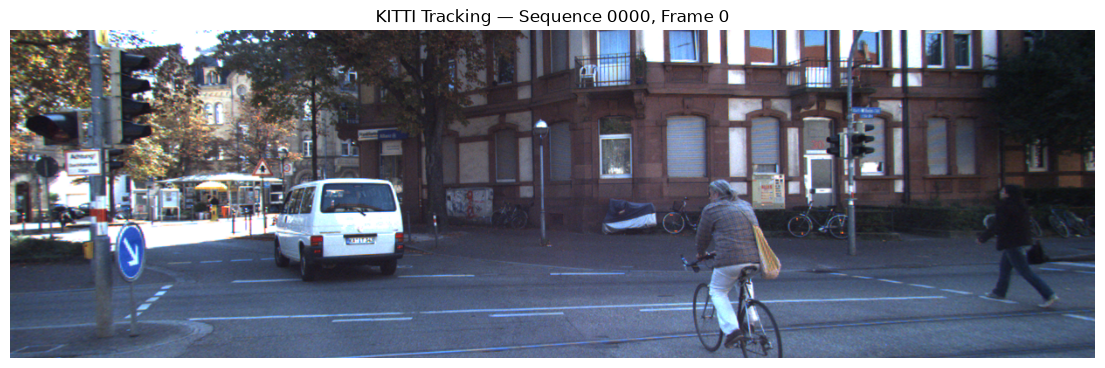


Label file exists: True
Calibration file exists: True

First five annotation lines:
0 -1 DontCare -1 -1 -10.000000 219.310000 188.490000 245.500000 218.560000 -1000.000000 -1000.000000 -1000.000000 -10.000000 -1.000000 -1.000000 -1.000000
0 -1 DontCare -1 -1 -10.000000 47.560000 195.280000 115.480000 221.480000 -1000.000000 -1000.000000 -1000.000000 -10.000000 -1.000000 -1.000000 -1.000000
0 0 Van 0 0 -1.793451 296.744956 161.752147 455.226042 292.372804 2.000000 1.823255 4.433886 -4.552284 1.858523 13.410495 -2.115488
0 1 Cyclist 0 0 -1.936993 737.619499 161.531951 931.112229 374.000000 1.739063 0.824591 1.785241 1.640400 1.675660 5.776261 -1.675458
0 2 Pedestrian 0 0 -2.523309 1106.137292 166.576807 1204.470628 323.876144 1.714062 0.767881 0.972283 6.301919 1.652419 8.455685 -1.900245


In [2]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np

# Project paths
PROJECT_ROOT = Path.home() / "UltraCNN"
TRACKING_ROOT = PROJECT_ROOT / "data" / "kitti" / "tracking"

IMAGE_ROOT = (
    TRACKING_ROOT
    / "data_tracking_image_2"
    / "training"
    / "image_02"
)

LABEL_ROOT = (
    TRACKING_ROOT
    / "data_tracking_label_2"
    / "training"
    / "label_02"
)

CALIB_ROOT = (
    TRACKING_ROOT
    / "data_tracking_calib"
    / "training"
    / "calib"
)

SEQUENCE_ID = "0000"
SEQUENCE_DIR = IMAGE_ROOT / SEQUENCE_ID

# Find frames
frame_paths = sorted(SEQUENCE_DIR.glob("*.png"))

print("Sequence:", SEQUENCE_ID)
print("Sequence directory exists:", SEQUENCE_DIR.exists())
print("Total frames:", len(frame_paths))

if frame_paths:
    print("First frame:", frame_paths[0].name)
    print("Last frame:", frame_paths[-1].name)

    # Display the first frame
    first_frame = cv2.imread(str(frame_paths[0]))

    plt.figure(figsize=(14, 5))
    plt.imshow(cv2.cvtColor(first_frame, cv2.COLOR_BGR2RGB))
    plt.title(f"KITTI Tracking — Sequence {SEQUENCE_ID}, Frame 0")
    plt.axis("off")
    plt.show()

# Inspect annotation and calibration files
label_path = LABEL_ROOT / f"{SEQUENCE_ID}.txt"
calib_path = CALIB_ROOT / f"{SEQUENCE_ID}.txt"

print("\nLabel file exists:", label_path.exists())
print("Calibration file exists:", calib_path.exists())

if label_path.exists():
    print("\nFirst five annotation lines:")
    with label_path.open() as f:
        for _, line in zip(range(5), f):
            print(line.rstrip())

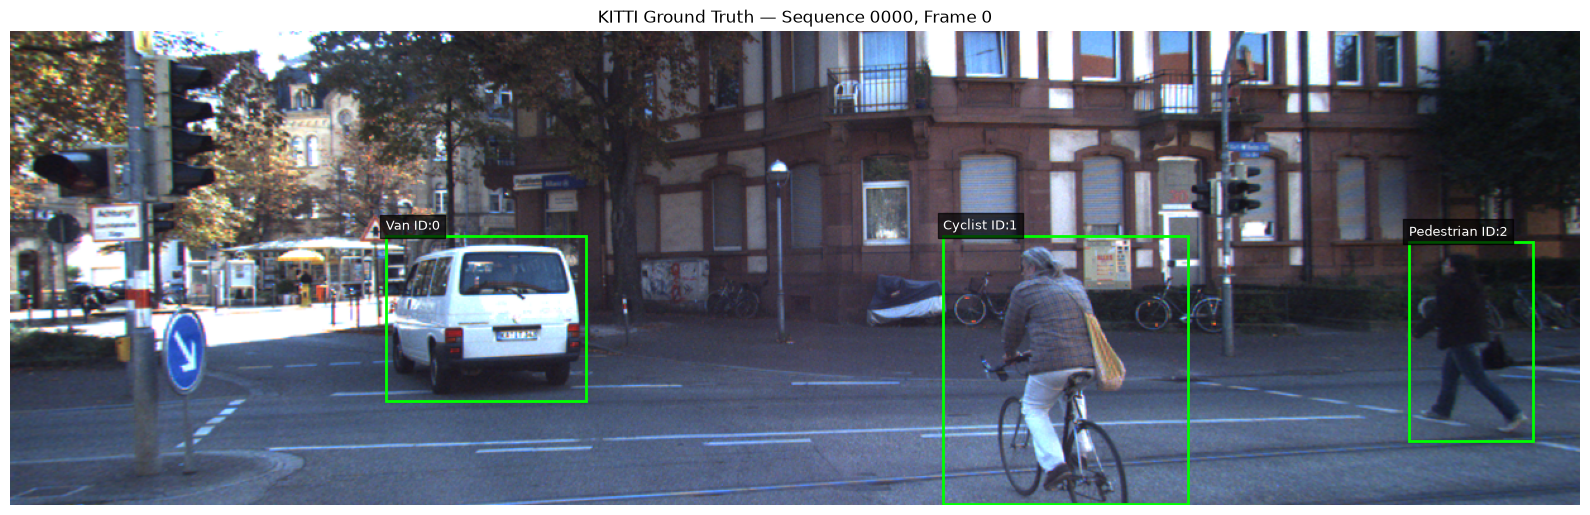

In [3]:
# Visualize KITTI ground-truth annotations on frame 0

import matplotlib.pyplot as plt
import matplotlib.patches as patches

frame_index = 0
frame_path = SEQUENCE_DIR / f"{frame_index:06d}.png"

image = cv2.imread(str(frame_path))
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(figsize=(16, 7))
ax.imshow(image)

with label_path.open() as f:
    for line in f:
        fields = line.strip().split()

        if len(fields) < 17:
            continue

        frame_id = int(fields[0])
        track_id = int(fields[1])
        object_class = fields[2]

        # Only draw annotations for the selected frame
        if frame_id != frame_index:
            continue

        # Ignore DontCare regions for this visualization
        if object_class == "DontCare":
            continue

        x1, y1, x2, y2 = map(float, fields[6:10])

        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=2,
            edgecolor="lime",
            facecolor="none"
        )
        ax.add_patch(rect)

        ax.text(
            x1,
            max(0, y1 - 5),
            f"{object_class} ID:{track_id}",
            color="white",
            fontsize=9,
            bbox=dict(facecolor="black", alpha=0.7)
        )

ax.set_title(f"KITTI Ground Truth — Sequence {SEQUENCE_ID}, Frame {frame_index}")
ax.axis("off")
plt.tight_layout()
plt.show()

In [4]:
from ultralytics import YOLO
import torch

model = YOLO("yolo11n.pt")

TRACK_FRAMES = 30
CONF_THRESHOLD = 0.20

frame_paths = sorted(SEQUENCE_DIR.glob("*.png"))[:TRACK_FRAMES]

print("Frames to process:", len(frame_paths))
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")

tracking_results = model.track(
    source=[str(path) for path in frame_paths],
    tracker="bytetrack.yaml",
    persist=True,
    conf=CONF_THRESHOLD,
    imgsz=640,
    device=0 if torch.cuda.is_available() else "cpu",
    stream=True,
    verbose=False
)

tracking_summary = []

for frame_number, result in enumerate(tracking_results):
    boxes = result.boxes

    if boxes is None or len(boxes) == 0:
        continue

    for box in boxes:
        class_id = int(box.cls[0])
        class_name = model.names[class_id]

        track_id = (
            int(box.id[0])
            if box.id is not None
            else None
        )

        x1, y1, x2, y2 = box.xyxy[0].tolist()

        tracking_summary.append({
            "frame": frame_number,
            "track_id": track_id,
            "class_id": class_id,
            "class": class_name,
            "confidence": float(box.conf[0]),
            "x1": x1,
            "y1": y1,
            "x2": x2,
            "y2": y2
        })

print("Total detections:", len(tracking_summary))
print(
    "Unique tracked IDs:",
    len({
        item["track_id"]
        for item in tracking_summary
        if item["track_id"] is not None
    })
)

print("\nDetected classes:")
for class_name, count in sorted(
    __import__("collections").Counter(
        item["class"] for item in tracking_summary
    ).items()
):
    print(f"{class_name}: {count}")

Frames to process: 30
Device: GPU
Total detections: 138
Unique tracked IDs: 18

Detected classes:
bicycle: 62
bus: 2
car: 29
handbag: 1
person: 34
stop sign: 1
traffic light: 4
truck: 5


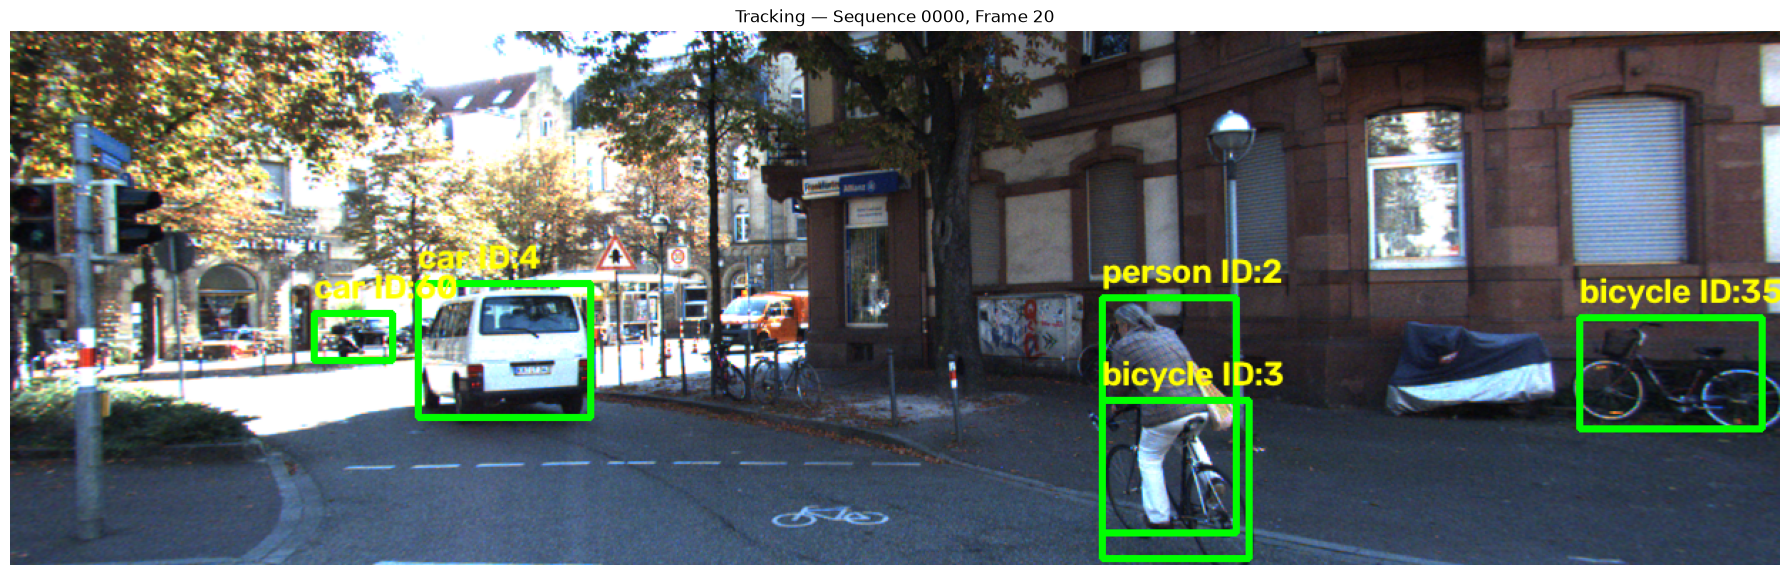

In [10]:
# Cell 4: Display one large tracking frame

FRAME_TO_SHOW = 20  # Try 0, 5, 10, 15, 20, 25, or 29

frame_path = frame_paths[FRAME_TO_SHOW]
image = cv2.imread(str(frame_path))

# Draw tracked vehicles
for item in tracking_summary:
    if item["frame"] != FRAME_TO_SHOW:
        continue

    x1, y1, x2, y2 = map(
        int, [item["x1"], item["y1"], item["x2"], item["y2"]]
    )

    track_id = item["track_id"]
    label = f'{item["class"]} ID:{track_id}'

    cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 3)

    cv2.putText(
        image,
        label,
        (x1, max(y1 - 10, 25)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 255, 255),
        2
    )

# Display at a larger size
plt.figure(figsize=(18, 9))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title(f"Tracking — Sequence {SEQUENCE_ID}, Frame {FRAME_TO_SHOW}")
plt.axis("off")
plt.tight_layout()
plt.show()